## BCG Dataset Analysis

This script analyses the BCG datasets folds.

In [15]:
import scipy.io as sio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gs
from pathlib import Path

NUM_FOLDS = 5
FOLD = 0

In [ ]:
def load_fold(fold):
    mabp = sio.loadmat(f'bcg_dataset/signal_mabp_fold_{fold}.mat')
    features = pd.read_csv(f'bcg_dataset/feat_fold_{fold}.csv')

    return {
        'ppg': mabp['signal'],  # (N, 625), normalized ot [0,1]
        'abp': mabp['abp_signal'],  # (N,164), mmHg values
        'SP': mabp['SP'].flatten(), # (N,1)
        'DP': mabp['DP'].flatten(), # (N,1)
        'limits': mabp['class_limits'], # (N,4)
        'patient': mabp['patient'].flatten(),   # (N,1)
        'feat': features,
        'fold': fold,
        'N': mabp['signal'].shape[0]
    }

def load_all_folds():
    folds = [load_fold(i) for i in range(NUM_FOLDS)]
    return {
        'abp'    : np.concatenate([f['abp']    for f in folds]),
        'ppg'    : np.concatenate([f['ppg']    for f in folds]),
        'limits' : np.concatenate([f['limits'] for f in folds]),
        'SP'     : np.concatenate([f['SP']     for f in folds]),
        'DP'     : np.concatenate([f['DP']     for f in folds]),
        'patient': np.concatenate([f['patient']for f in folds]),
        'feat'   : pd.concat([f['feat'] for f in folds], ignore_index=True),
        'N'      : sum(f['N'] for f in folds),
    }

def summary(d):
    fold_label = f"Fold {d['fold']}" if 'fold' in d else 'All folds'
    print(f"{'='*52}")
    print(f"  {fold_label}  —  {d['N']} samples")
    print(f"{'='*52}")
    print(f"  abp_signal  : {d['abp'].shape}  "
          f"[{d['abp'].min():.1f}, {d['abp'].max():.1f}] mmHg")
    print(f"  ppg         : {d['ppg'].shape}  "
          f"[{d['ppg'].min():.3f}, {d['ppg'].max():.3f}]")
    print(f"  class_limits: {d['limits'].shape}")
    for i, name in enumerate(['sys_peak', 'dicrotic_notch', 'dia_trough', 'next_onset']):
        col = d['limits'][:, i]
        print(f"    col {i} ({name:16s}): "
              f"min={col.min():3d}  max={col.max():3d}  mean={col.mean():.1f}")
    print(f"  SP          : {d['SP'].min():.1f} – {d['SP'].max():.1f} mmHg  "
          f"(mean {d['SP'].mean():.1f})")
    print(f"  DP          : {d['DP'].min():.1f} – {d['DP'].max():.1f} mmHg  "
          f"(mean {d['DP'].mean():.1f})")
    n_patients = len(np.unique(d['patient']))
    print(f"  Patients    : {n_patients}")
    print(f"  Features    : {d['feat'].shape[1] - 4} (excl. patient/trial/SP/DP)")

f = load_fold(FOLD)
ALL = load_all_folds()
summary(ALL)
for i in range(5):
    fold = load_fold(i)
    summary(fold)

  All folds  —  3063 samples
  abp_signal  : (3063, 164)  [43.9, 190.2] mmHg
  ppg         : (3063, 625)  [-0.176, 0.788]
  class_limits: (3063, 4)
    col 0 (sys_peak        ): min= 12  max= 52  mean=17.7
    col 1 (dicrotic_notch  ): min= 26  max= 84  mean=51.2
    col 2 (dia_trough      ): min= 44  max=149  mean=117.9
    col 3 (next_onset      ): min= 59  max=164  mean=132.9
  SP          : 71.7 – 191.1 mmHg  (mean 121.0)
  DP          : 44.5 – 100.7 mmHg  (mean 67.2)
  Patients    : 40
  Features    : 218 (excl. patient/trial/SP/DP)
  Fold 0  —  671 samples
  abp_signal  : (671, 164)  [53.1, 190.2] mmHg
  ppg         : (671, 625)  [-0.094, 0.469]
  class_limits: (671, 4)
    col 0 (sys_peak        ): min= 14  max= 26  mean=18.7
    col 1 (dicrotic_notch  ): min= 30  max= 84  mean=51.1
    col 2 (dia_trough      ): min= 44  max=149  mean=114.8
    col 3 (next_onset      ): min= 59  max=164  mean=129.8
  SP          : 94.9 – 191.1 mmHg  (mean 130.6)
  DP          : 53.3 – 100.7 mmHg

## SP/DP Distribution

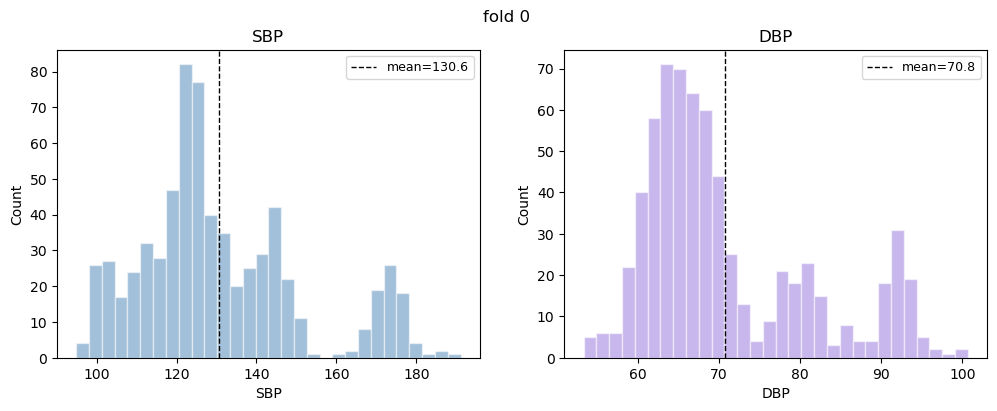

In [17]:
def plot_bp_distribution(data, title=''):
    SP, DP = data['SP'], data['DP']
    MABP = (SP + 2*DP) / 3   # Mean Arterial Blood Pressure

    fig, axes = plt.subplots(1,2, figsize=(12,4))
    fig.suptitle(title)

    for ax, values, label, color in zip(axes, [SP, DP], ['SBP', 'DBP'], ['steelblue', 'mediumpurple']):
        ax.hist(values, bins=30, color=color, alpha=0.5, edgecolor='white')
        ax.axvline(values.mean(), color='black', linestyle='--', linewidth=1.0,
                   label=f'mean={values.mean():.1f}')
        ax.set_xlabel(f'{label}')
        ax.set_ylabel('Count')
        ax.set_title(label)
        ax.legend(fontsize=9)
    

plot_bp_distribution(f, title=f'fold {FOLD}')

## ABP waveform

The following cell plots the ABP signal with its 4 class_limit values:
- Systolic peak (SBP value)
- Dicrotic notch
- Diastolic valley (DBP value)
- onset of next recording

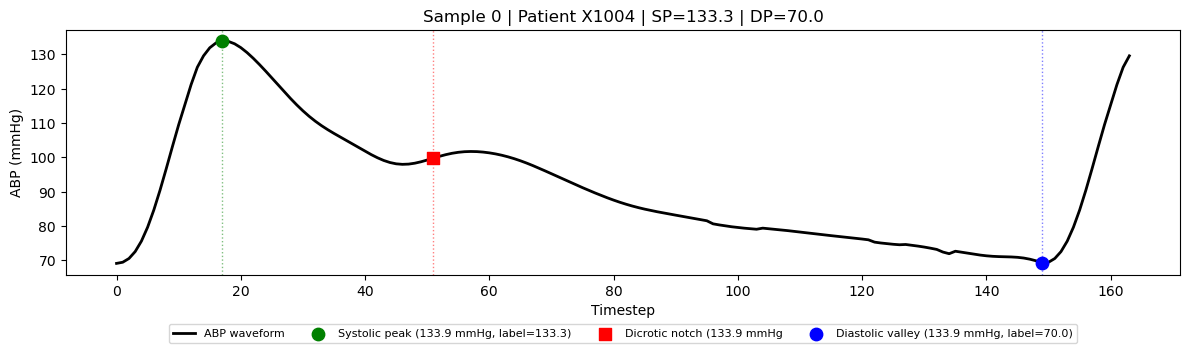

In [18]:
def plot_abp_waveform(data, sample_idx=0):
    abp = data['abp'][sample_idx]
    limits = data['limits'][sample_idx]
    sp = data['SP'][sample_idx]
    dp = data['DP'][sample_idx]
    patient = data['patient'][sample_idx]

    fig, ax = plt.subplots(figsize=(12,4))
    ax.plot(abp, color='black', linewidth=2.0, label='ABP waveform')

    class_limits = [
        (limits[0], abp[limits[0]], 'green', 'o', f'Systolic peak ({abp[limits[0]]:.1f} mmHg, label={sp:.1f})'),
        (limits[1], abp[limits[1]], 'red', 's', f'Dicrotic notch ({abp[limits[0]]:.1f} mmHg'),
        (limits[2], abp[limits[2]], 'blue', 'o', f'Diastolic valley ({abp[limits[0]]:.1f} mmHg, label={dp:.1f})')
        ]
    if limits[3] < len(abp):
        class_limits.append(
            (limits[3], abp[limits[3]], 'mediumpurple', '^', f'Next onset ({abp[limits[3]]:.1f} mmHg)')
        )
    
    for t, value, color, cl, label in class_limits:
        ax.axvline(t,color=color, linestyle=':', alpha=0.5, linewidth=1.0)
        ax.scatter(t, value, color=color, marker=cl, s=80, zorder=5, label=label)
    
    ax.set_xlabel('Timestep')
    ax.set_ylabel('ABP (mmHg)')
    ax.set_title(f'Sample {sample_idx} | Patient {patient} | SP={sp:.1f} | DP={dp:.1f}')
    ax.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=True)
    plt.tight_layout()
    plt.subplots_adjust(bottom=0.3)

plot_abp_waveform(f, sample_idx=0)

## Landmark Alignment Check

Checks how accurately the class_limits[0] and class_limits[2] represent the actual SB and DP values respectively

Systolic Mean Error: 0.05 mmHg 
std: 0.71 
MAE: 0.36
Diastolic    Mean Error: 0.02 mmHg 
std: 0.65 
MAE: 0.42


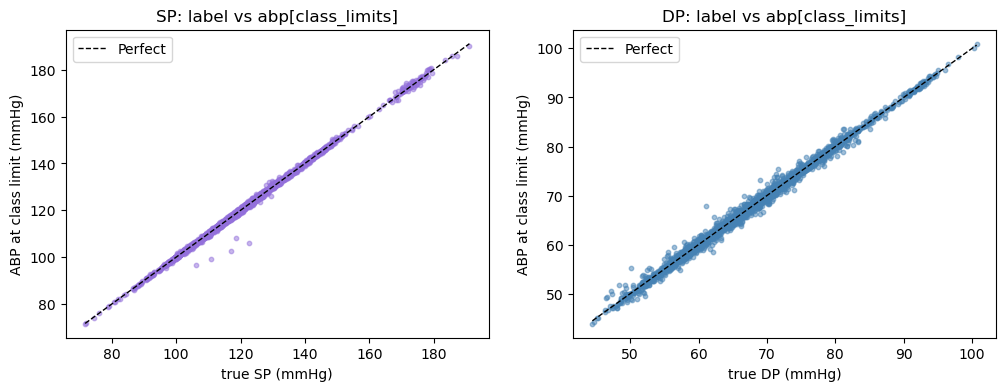

In [19]:
def class_limits_alignment(data):
    abp = data['abp']
    limits = data['limits']
    SP, DP = data['SP'], data['DP']

    sp_values = abp[np.arange(data['N']), limits[:,0]]
    dp_values = abp[np.arange(data['N']), limits[:,2]]
    
    error_sp = sp_values - SP
    error_dp = dp_values - DP

    print(f'Systolic Mean Error: {error_sp.mean():.2f} mmHg \nstd: {error_sp.std():.2f} \nMAE: {np.abs(error_sp).mean():.2f}')
    print(f'Diastolic    Mean Error: {error_dp.mean():.2f} mmHg \nstd: {error_dp.std():.2f} \nMAE: {np.abs(error_dp).mean():.2f}')

    fig, axes = plt.subplots(1,2, figsize=(12,4))

    for ax, true_values, limit_values, label, color in zip(axes, [SP,DP], [sp_values, dp_values], ['SP', 'DP'], ['mediumpurple', 'steelblue']):
        ax.scatter(true_values, limit_values, alpha=0.5, s=10, color=color)
        min, max = true_values.min(), true_values.max()
        ax.plot([min,max], [min,max], 'k--', linewidth=1, label='Perfect')
        ax.set_xlabel(f'true {label} (mmHg)')
        ax.set_ylabel(f'ABP at class limit (mmHg)')
        ax.set_title(f'{label}: label vs abp[class_limits]')
        ax.legend(fontsize=10)
    
    
    plt.show()


class_limits_alignment(ALL)

## Mean ABP waveform ± std

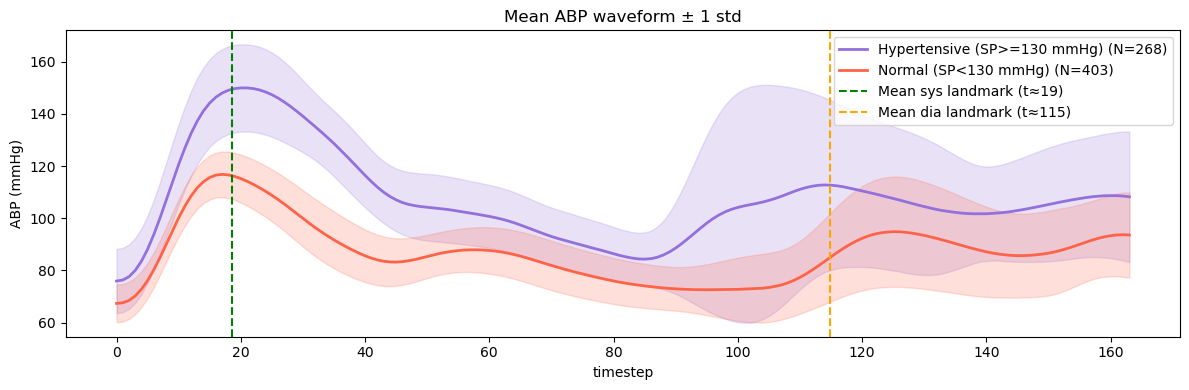

In [20]:
def plot_meanABP_waveform(data, split=True):
    abp = data['abp']
    SP = data['SP']

    fig,ax = plt.subplots(figsize=(12,4))
    
    if split:
        groups = {
            'Hypertensive (SP>=130 mmHg)': abp[SP >= 130],
            'Normal (SP<130 mmHg)': abp[SP < 130]
        }

        colors = ['mediumpurple', 'tomato']
        for (label, group), color in zip(groups.items(), colors):
            mean = group.mean(0)    # take the mean across the time dimension (not the entry dimension)
            std = group.std(0)
            ax.plot(mean, color=color, linewidth=2.0, label=f'{label} (N={len(group)})')
            ax.fill_between(range(164), mean - std, mean + std, color=color, alpha=0.2)
    
    else: 
        mean = abp.mean(0)
        std = abp.std(0)
        ax.plot(mean, color='mediumpurple', linewidth=2.0, label='Mean ABP')
        ax.fill_between(range(164), mean - std, mean + std, color='mediumpurple', alpha=0.2, label='±1 std')

    limit = data['limits']
    ax.axvline(limit[:,0].mean(), color='green', linestyle='--', linewidth=1.5, label=f'Mean sys landmark (t≈{limit[:,0].mean():.0f})')
    ax.axvline(limit[:,2].mean(), color='orange', linestyle='--', linewidth=1.5, label=f'Mean dia landmark (t≈{limit[:,2].mean():.0f})')
    ax.set_xlabel('timestep')
    ax.set_ylabel('ABP (mmHg)')
    ax.set_title('Mean ABP waveform ± 1 std')
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.show()

plot_meanABP_waveform(f)

## Class_limits Diagnosis

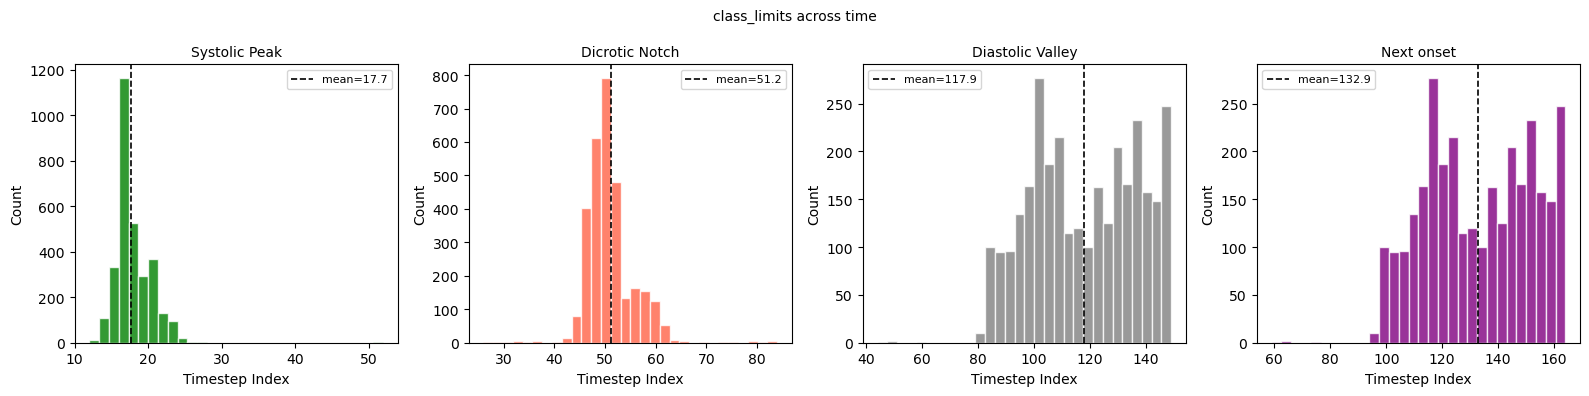

Inter-limit intervals (mean ± std)
sys -> notch: 33.5 ± 4.2 steps
notch -> dia: 66.7 ± 17.9 steps
dia -> next: 15.0 ± 0.0 steps
sys -> dia: 100.2 ± 19.4 steps


In [21]:
def plot_class_limits_diagnostic(data):
    limit = data['limits']
    names = ['Systolic Peak', 'Dicrotic Notch', 'Diastolic Valley', 'Next onset']
    colors = ['green', 'tomato', 'gray', 'purple']

    fig, axes = plt.subplots(1,4,figsize=(16,4))
    fig.suptitle('class_limits across time', fontsize=10)

    for ax, column, name, color in zip(axes, range(4), names, colors):
        values = limit[:,column]
        ax.hist(values, bins=30, color=color, alpha=0.8, edgecolor='white')
        ax.axvline(values.mean(), color='black', linestyle='--', linewidth=1.2, label=f'mean={values.mean():.1f}')
        ax.set_title(name, fontsize=10)
        ax.set_xlabel('Timestep Index')
        ax.set_ylabel('Count')
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

    # this prints the amount of time inbetween different class_limit values, e.g. sys -> dia measures the time where the 
    # kernel will need to fire to elevate the output signal  to match the ABP signal using the spikes. 
    print('Inter-limit intervals (mean ± std)')
    intervals = {
        'sys -> notch': limit[:,1] - limit[:,0],
        'notch -> dia': limit[:,2] - limit[:,1],
        'dia -> next': limit[:,3] - limit[:,2],
        'sys -> dia': limit[:,2] - limit[:,0],
    }
    for name, values in intervals.items():
        print(f'{name}: {values.mean():.1f} ± {values.std():.1f} steps')

plot_class_limits_diagnostic(ALL)